# Crew data analysis

In [16]:
import pandas as pd
import seaborn as sns
import plotly.express as px
from matplotlib import pyplot as plt
from pygments.lexers import go

df_crew = pd.read_csv('../data/crew.csv')
df_movies = pd.read_csv('../data/movies.csv')
df_movies_selected = df_movies[['id', 'name', 'date', 'rating']]
df_crew_joined_movies = df_crew.merge(df_movies_selected, on='id', how='left')
df_crew_joined_movies = df_crew_joined_movies.rename(columns={'name_x': 'crew_name', 'name_y': 'movie_name'})
df_crew_joined_movies.head()

,id,role,crew_name,movie_name,date,rating
0,1000001,Director,Greta Gerwig,Barbie,2023.0,3.86
1,1000001,Producer,Tom Ackerley,Barbie,2023.0,3.86
2,1000001,Producer,Margot Robbie,Barbie,2023.0,3.86
3,1000001,Producer,Robbie Brenner,Barbie,2023.0,3.86
4,1000001,Producer,David Heyman,Barbie,2023.0,3.86


- We want the crew size for each movie with the rating

In [17]:
df_grouped_crew = df_crew_joined_movies.groupby(['id', 'movie_name']).agg(
    {'crew_name': 'size', 'rating': 'mean'}).reset_index()
df_grouped_crew.rename(columns={'crew_name': 'crew_size'}, inplace=True)
df_grouped_crew.head(15)

,id,movie_name,crew_size,rating
0,1000001,Barbie,141,3.86
1,1000002,Parasite,71,4.56
2,1000003,Everything Everywhere All at Once,87,4.30
3,1000004,Fight Club,79,4.27
4,1000005,La La Land,86,4.09
5,1000006,Oppenheimer,75,4.23
6,1000007,Interstellar,138,4.35
7,1000008,Joker,104,3.85
8,1000009,Dune,190,3.90
9,1000010,Pulp Fiction,48,4.26


## Distribution of crew size and rating
we want to see the distribution of the crew size in relation with the rating, and we want to see if there is a correlation between the two

5.8486110078556734


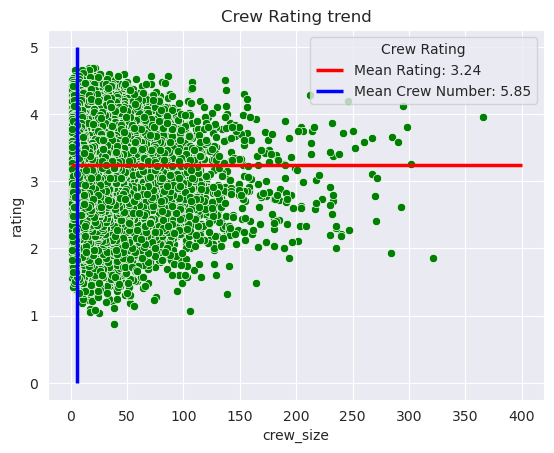

In [18]:
mean_rating = df_grouped_crew['rating'].mean()
mean_crew_number = df_grouped_crew['crew_size'].mean()
sns.scatterplot(data=df_grouped_crew, x='crew_size', y='rating', color='green')
plt.title('Crew Rating trend')
print(mean_crew_number)
plt.hlines(mean_rating, 0, 400, colors='red', linewidth=2.5, label=f'Mean Rating: {mean_rating:.2f}')
plt.vlines(mean_crew_number, 0, 5, colors='blue', linewidth=2.5, label=f'Mean Crew Number: {mean_crew_number:.2f}')
plt.legend(title='Crew Rating', loc='upper right')
plt.show()

At first glance, it seems that there is no correlation between the crew size and the rating, but we can see if the movies with larger crews have a higher rating
---
only 14.3% of the movies with a crew size greater than the mean have a rating greater than the mean.


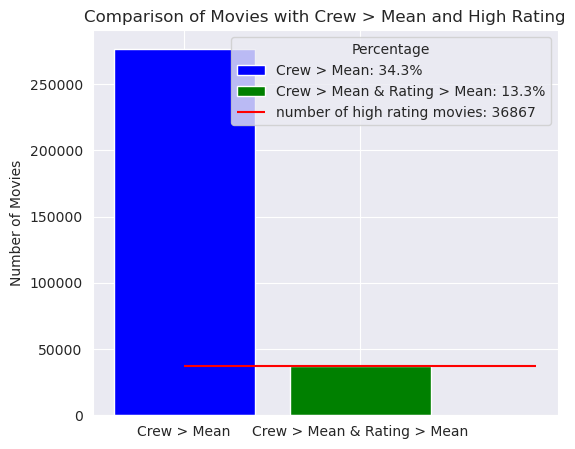

In [19]:
df_grouped_crew_upmean = df_grouped_crew[df_grouped_crew['crew_size'] > mean_crew_number]

number_of_movies_upmean = df_grouped_crew_upmean.shape[0]

number_of_movies_upmean_rating = df_grouped_crew_upmean[df_grouped_crew_upmean['rating'] > mean_rating].shape[0]

plt.figure(figsize=(6, 5))
perc_large_crew = df_grouped_crew_upmean.shape[0] / df_grouped_crew.shape[0] * 100
perc_high_rating = number_of_movies_upmean_rating / number_of_movies_upmean * 100
plt.bar(['Crew > Mean', 'Crew > Mean & Rating > Mean'],
        [number_of_movies_upmean, number_of_movies_upmean_rating],
        color=['blue', 'green'], label=[f'Crew > Mean: {perc_large_crew:.1f}%', f'Crew > Mean & Rating > Mean: {perc_high_rating:.1f}%'])
plt.ylabel("Number of Movies")
plt.hlines(number_of_movies_upmean_rating, 0, 2, colors='red', label=f'number of high rating movies: {number_of_movies_upmean_rating}')
plt.title("Comparison of Movies with Crew > Mean and High Rating")
plt.legend(title="Percentage", loc="upper right")

plt.show()

- We want to add another column to the dataframe that contains the number of directors for each movie
- Display the top 15 movies with the highest rating and the number of directors for each

In [20]:
df_directors = df_crew_joined_movies[df_crew_joined_movies['role'] == 'Director']
df_directors = df_directors.groupby(['id', 'movie_name']).agg({'role': 'count'}).reset_index()
df_final_gruoped_crew = df_grouped_crew.merge(df_directors, on=['id', 'movie_name'], how='left',
                                              suffixes=('_crew', '_director'))
#it is necessary remove the duplicates because there are multiple directors for each movie
df_final_gruoped_crew = df_final_gruoped_crew.drop_duplicates(subset=['id', 'movie_name'], keep='first')
df_final_gruoped_crew = df_final_gruoped_crew.rename(columns={'role': 'director_count'})
df_final_gruoped_crew = df_final_gruoped_crew.sort_values('rating', ascending=False)
df_final_gruoped_crew.head(15)

,id,movie_name,crew_size,rating,director_count
1982,1001983,Band of Brothers,20,4.69,8.0
863,1000864,Harakiri,16,4.69,1.0
1236,1001237,Stop Making Sense,22,4.68,1.0
4267,1004268,Radiohead: In Rainbows – From the Basement,10,4.66,1.0
3223,1003224,No Half Measures: Creating the Final Season of...,4,4.65,1.0
1635,1001636,Cowboy Bebop,17,4.65,6.0
3376,1003377,Fullmetal Alchemist: Brotherhood,16,4.65,2.0
3447,1003448,Monster,8,4.64,2.0
431,1000432,Come and See,14,4.64,1.0
238,1000239,12 Angry Men,16,4.62,1.0


## Heatmap
We can see:
 - a obvious  correlation between the directors count and the crew size
 - a small correlation between the rating and the number of directors
  - a small negative correlation between the crew size and rating

 But in general, the correlations is very weak

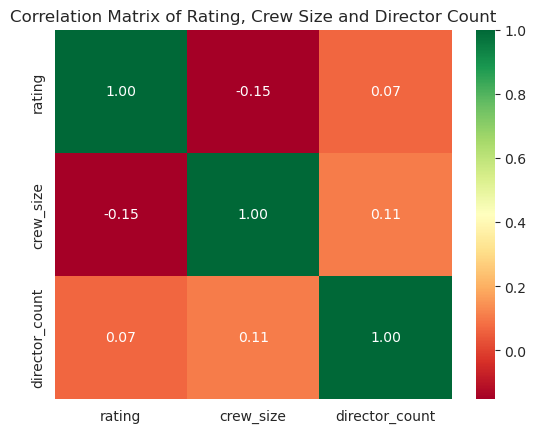

In [21]:
correlation_matrix = df_final_gruoped_crew[['rating','crew_size','director_count']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='RdYlGn', fmt='.2f')
plt.title('Correlation Matrix of Rating, Crew Size and Director Count')
plt.show()